Dataset created successfully
X shape: (300, 10)
y shape: (300,)

Training samples: 240
Validation samples: 60


REGULARISATION COMPARISON RESULTS
      C  Lasso_val_acc  Ridge_val_acc  ElasticNet_val_acc  Lasso_nonzero  Ridge_nonzero
  0.001       0.466667       0.900000            0.466667              0             10
  0.010       0.466667       0.916667            0.716667              0             10
  0.100       0.900000       0.933333            0.933333              4             10
  1.000       0.916667       0.916667            0.916667              9             10
 10.000       0.916667       0.916667            0.916667             10             10
100.000       0.916667       0.916667            0.916667             10             10


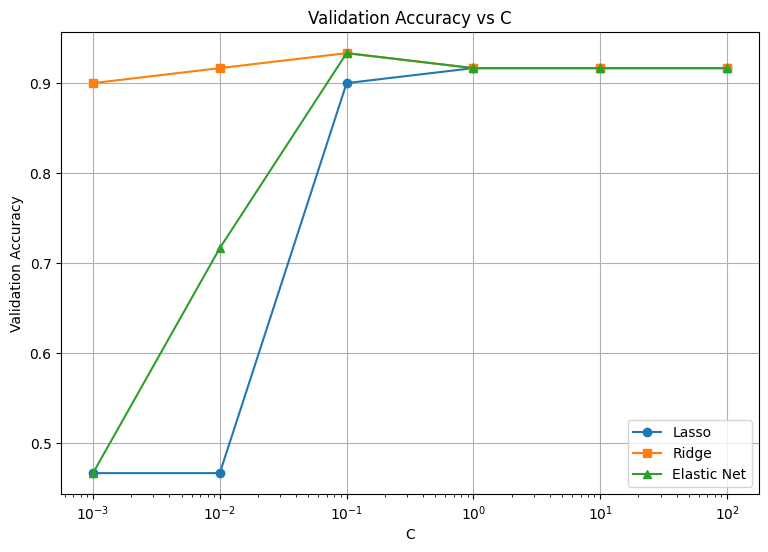

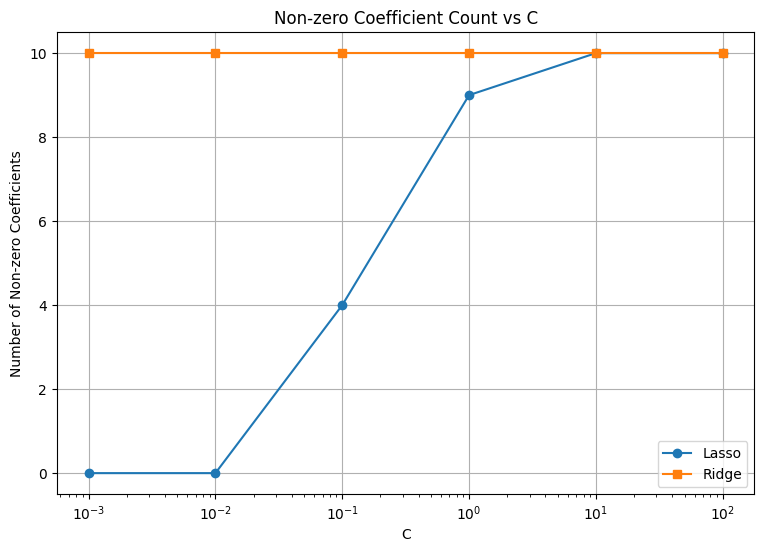

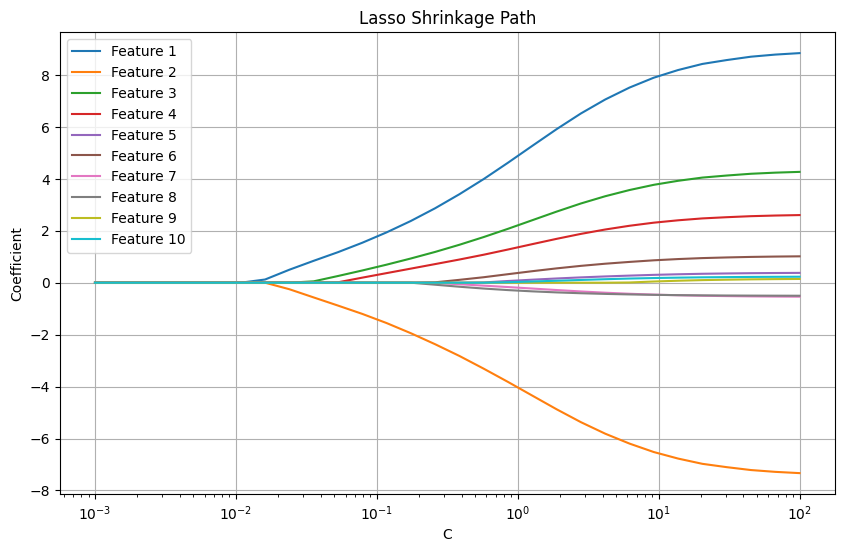

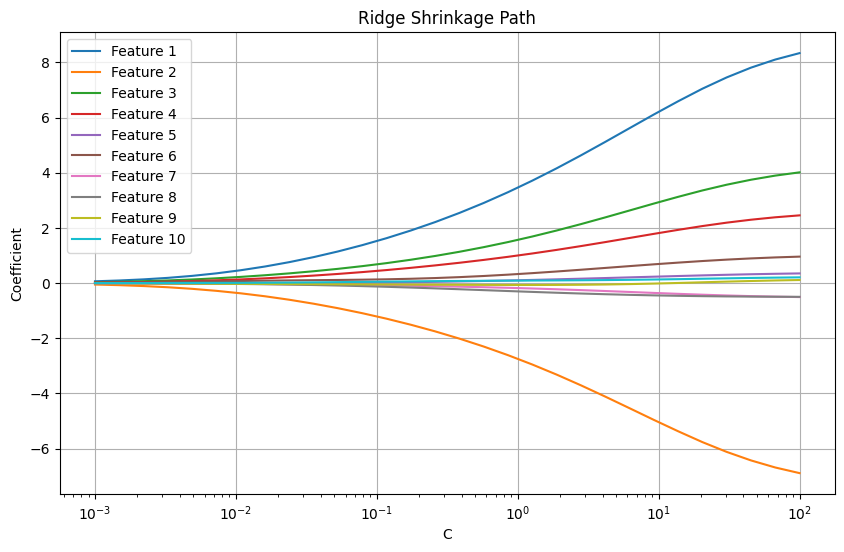

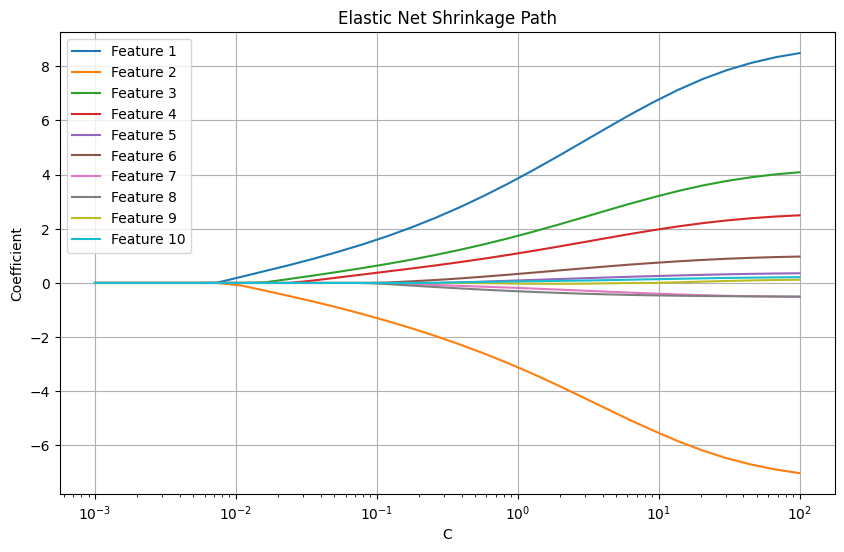

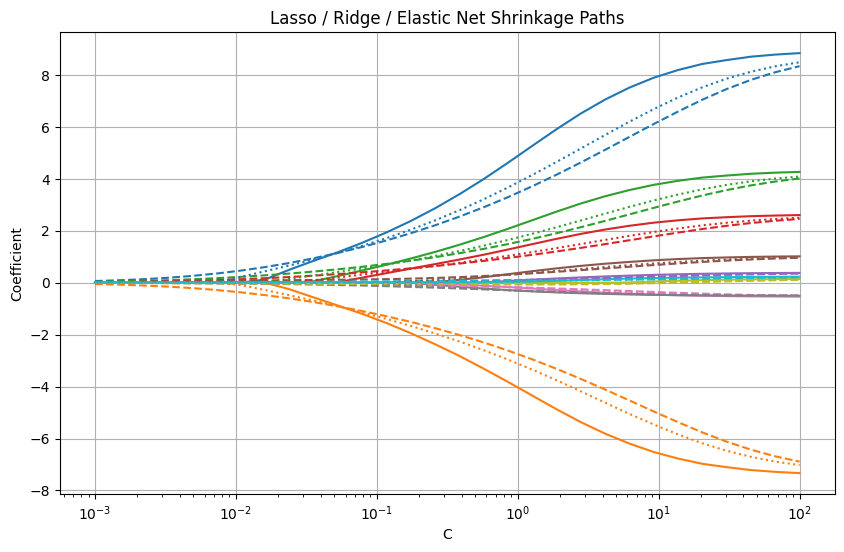



FINAL DATAFRAME


,C,Lasso_val_acc,Ridge_val_acc,ElasticNet_val_acc,Lasso_nonzero,Ridge_nonzero
0,0.001,0.466667,0.900000,0.466667,0,10
1,0.010,0.466667,0.916667,0.716667,0,10
2,0.100,0.900000,0.933333,0.933333,4,10
3,1.000,0.916667,0.916667,0.916667,9,10
4,10.000,0.916667,0.916667,0.916667,10,10
5,100.000,0.916667,0.916667,0.916667,10,10



Results saved as regularisation_comparison.csv


ANALYSIS

1. Lasso uses L1 regularisation.
   It can reduce some coefficients exactly to zero.

2. Ridge uses L2 regularisation.
   It shrinks coefficients toward zero but normally
   does not make them exactly zero.

3. Elastic Net combines L1 and L2 regularisation.

4. Small C means stronger regularisation.

5. Large C means weaker regularisation.

6. The validation accuracy graph shows how prediction
   accuracy changes with different regularisation strengths.

7. The non-zero coefficient graph shows the sparsity
   produced by the regularisation methods.

8. Shrinkage paths show how model coefficients change
   as C changes.



In [ ]:

# 1. IMPORT LIBRARIES


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score


# ------------------------------------------------------------
# 2. CREATE SAMPLE DATASET
# ------------------------------------------------------------

np.random.seed(42)

# 300 samples and 10 features
X = np.random.randn(300, 10)

# Create binary target
y = (
    2 * X[:, 0]
    - 1.5 * X[:, 1]
    + 1.0 * X[:, 2]
    + 0.5 * X[:, 3]
    + np.random.randn(300) * 0.5
    > 0
).astype(int)


print("Dataset created successfully")
print("X shape:", X.shape)
print("y shape:", y.shape)


# ------------------------------------------------------------
# 3. TRAIN-VALIDATION SPLIT
# ------------------------------------------------------------

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)


# ------------------------------------------------------------
# 4. FEATURE SCALING
# ------------------------------------------------------------

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_val = scaler.transform(X_val)


print("\nTraining samples:", X_train.shape[0])
print("Validation samples:", X_val.shape[0])


# ------------------------------------------------------------
# 5. FUNCTION: compare_regularisation()
# ------------------------------------------------------------

def compare_regularisation(
    X_train,
    y_train,
    X_val,
    y_val,
    C_values
):

    results = []

    # Loop through different C values
    for C in C_values:

        # ====================================================
        # LASSO - L1 REGULARISATION
        # ====================================================

        lasso = LogisticRegression(
            penalty='l1',
            solver='liblinear',
            C=C,
            max_iter=1000
        )

        lasso.fit(
            X_train,
            y_train
        )

        lasso_pred = lasso.predict(
            X_val
        )

        lasso_val_acc = accuracy_score(
            y_val,
            lasso_pred
        )

        # Count non-zero coefficients
        lasso_nonzero = np.sum(
            lasso.coef_ != 0
        )


        # ====================================================
        # RIDGE - L2 REGULARISATION
        # ====================================================

        ridge = LogisticRegression(
            penalty='l2',
            solver='liblinear',
            C=C,
            max_iter=1000
        )

        ridge.fit(
            X_train,
            y_train
        )

        ridge_pred = ridge.predict(
            X_val
        )

        ridge_val_acc = accuracy_score(
            y_val,
            ridge_pred
        )

        # Count non-zero coefficients
        ridge_nonzero = np.sum(
            ridge.coef_ != 0
        )


        # ====================================================
        # ELASTIC NET
        # ====================================================

        elastic = LogisticRegression(
            penalty='elasticnet',
            solver='saga',
            l1_ratio=0.5,
            C=C,
            max_iter=5000,
            random_state=42
        )

        elastic.fit(
            X_train,
            y_train
        )

        elastic_pred = elastic.predict(
            X_val
        )

        elastic_val_acc = accuracy_score(
            y_val,
            elastic_pred
        )


        # ====================================================
        # STORE RESULTS
        # ====================================================

        results.append([
            C,
            lasso_val_acc,
            ridge_val_acc,
            elastic_val_acc,
            lasso_nonzero,
            ridge_nonzero
        ])


    # --------------------------------------------------------
    # CREATE DATAFRAME
    # --------------------------------------------------------

    results_df = pd.DataFrame(
        results,
        columns=[
            'C',
            'Lasso_val_acc',
            'Ridge_val_acc',
            'ElasticNet_val_acc',
            'Lasso_nonzero',
            'Ridge_nonzero'
        ]
    )

    return results_df


# ------------------------------------------------------------
# 6. DIFFERENT REGULARISATION STRENGTHS
# ------------------------------------------------------------

C_values = [
    0.001,
    0.01,
    0.1,
    1,
    10,
    100
]


# ------------------------------------------------------------
# 7. CALL compare_regularisation()
# ------------------------------------------------------------

results = compare_regularisation(
    X_train,
    y_train,
    X_val,
    y_val,
    C_values
)


# ------------------------------------------------------------
# 8. DISPLAY RESULT DATAFRAME
# ------------------------------------------------------------

print("\n")
print("=" * 70)
print("REGULARISATION COMPARISON RESULTS")
print("=" * 70)

print(results.to_string(index=False))


# ------------------------------------------------------------
# 9. VALIDATION ACCURACY vs C
# ------------------------------------------------------------

plt.figure(figsize=(9, 6))

plt.semilogx(
    results['C'],
    results['Lasso_val_acc'],
    marker='o',
    label='Lasso'
)

plt.semilogx(
    results['C'],
    results['Ridge_val_acc'],
    marker='s',
    label='Ridge'
)

plt.semilogx(
    results['C'],
    results['ElasticNet_val_acc'],
    marker='^',
    label='Elastic Net'
)

plt.xlabel('C')
plt.ylabel('Validation Accuracy')

plt.title(
    'Validation Accuracy vs C'
)

plt.legend()

plt.grid(True)

plt.show()


# ------------------------------------------------------------
# 10. NON-ZERO COEFFICIENT COUNT
# ------------------------------------------------------------

plt.figure(figsize=(9, 6))

plt.semilogx(
    results['C'],
    results['Lasso_nonzero'],
    marker='o',
    label='Lasso'
)

plt.semilogx(
    results['C'],
    results['Ridge_nonzero'],
    marker='s',
    label='Ridge'
)

plt.xlabel('C')

plt.ylabel(
    'Number of Non-zero Coefficients'
)

plt.title(
    'Non-zero Coefficient Count vs C'
)

plt.legend()

plt.grid(True)

plt.show()


# ------------------------------------------------------------
# 11. SHRINKAGE PATHS
# ------------------------------------------------------------

# More C values for smooth curves

C_path = np.logspace(
    -3,
    2,
    30
)


# ============================================================
# LASSO COEFFICIENT PATH
# ============================================================

lasso_coefficients = []

for C in C_path:

    model = LogisticRegression(
        penalty='l1',
        solver='liblinear',
        C=C,
        max_iter=1000
    )

    model.fit(
        X_train,
        y_train
    )

    lasso_coefficients.append(
        model.coef_[0]
    )


lasso_coefficients = np.array(
    lasso_coefficients
)


plt.figure(figsize=(10, 6))

for i in range(
    lasso_coefficients.shape[1]
):

    plt.semilogx(
        C_path,
        lasso_coefficients[:, i],
        label=f'Feature {i+1}'
    )

plt.xlabel('C')

plt.ylabel('Coefficient')

plt.title(
    'Lasso Shrinkage Path'
)

plt.grid(True)

plt.legend()

plt.show()


# ============================================================
# RIDGE COEFFICIENT PATH
# ============================================================

ridge_coefficients = []

for C in C_path:

    model = LogisticRegression(
        penalty='l2',
        solver='liblinear',
        C=C,
        max_iter=1000
    )

    model.fit(
        X_train,
        y_train
    )

    ridge_coefficients.append(
        model.coef_[0]
    )


ridge_coefficients = np.array(
    ridge_coefficients
)


plt.figure(figsize=(10, 6))

for i in range(
    ridge_coefficients.shape[1]
):

    plt.semilogx(
        C_path,
        ridge_coefficients[:, i],
        label=f'Feature {i+1}'
    )

plt.xlabel('C')

plt.ylabel('Coefficient')

plt.title(
    'Ridge Shrinkage Path'
)

plt.grid(True)

plt.legend()

plt.show()


# ============================================================
# ELASTIC NET COEFFICIENT PATH
# ============================================================

elastic_coefficients = []

for C in C_path:

    model = LogisticRegression(
        penalty='elasticnet',
        solver='saga',
        l1_ratio=0.5,
        C=C,
        max_iter=5000,
        random_state=42
    )

    model.fit(
        X_train,
        y_train
    )

    elastic_coefficients.append(
        model.coef_[0]
    )


elastic_coefficients = np.array(
    elastic_coefficients
)


plt.figure(figsize=(10, 6))

for i in range(
    elastic_coefficients.shape[1]
):

    plt.semilogx(
        C_path,
        elastic_coefficients[:, i],
        label=f'Feature {i+1}'
    )

plt.xlabel('C')

plt.ylabel('Coefficient')

plt.title(
    'Elastic Net Shrinkage Path'
)

plt.grid(True)

plt.legend()

plt.show()


# ------------------------------------------------------------
# 12. COMBINED SHRINKAGE PATH
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))


# Lasso
for i in range(
    lasso_coefficients.shape[1]
):

    plt.semilogx(
        C_path,
        lasso_coefficients[:, i],
        linestyle='-'
    )


# Ridge
for i in range(
    ridge_coefficients.shape[1]
):

    plt.semilogx(
        C_path,
        ridge_coefficients[:, i],
        linestyle='--'
    )


# Elastic Net
for i in range(
    elastic_coefficients.shape[1]
):

    plt.semilogx(
        C_path,
        elastic_coefficients[:, i],
        linestyle=':'
    )


plt.xlabel('C')

plt.ylabel('Coefficient')

plt.title(
    'Lasso / Ridge / Elastic Net Shrinkage Paths'
)

plt.grid(True)

plt.show()


# ------------------------------------------------------------
# 13. FINAL DATAFRAME
# ------------------------------------------------------------

print("\n")
print("=" * 70)
print("FINAL DATAFRAME")
print("=" * 70)

display(results)


# ------------------------------------------------------------
# 14. SAVE RESULTS
# ------------------------------------------------------------

results.to_csv(
    'regularisation_comparison.csv',
    index=False
)

print(
    "\nResults saved as regularisation_comparison.csv"
)


# ------------------------------------------------------------
# 15. BASIC ANALYSIS
# ------------------------------------------------------------

print("\n")
print("=" * 70)
print("ANALYSIS")
print("=" * 70)

print("""
1. Lasso uses L1 regularisation.
   It can reduce some coefficients exactly to zero.

2. Ridge uses L2 regularisation.
   It shrinks coefficients toward zero but normally
   does not make them exactly zero.

3. Elastic Net combines L1 and L2 regularisation.

4. Small C means stronger regularisation.

5. Large C means weaker regularisation.

6. The validation accuracy graph shows how prediction
   accuracy changes with different regularisation strengths.

7. The non-zero coefficient graph shows the sparsity
   produced by the regularisation methods.

8. Shrinkage paths show how model coefficients change
   as C changes.
""")

Dataset created successfully
X shape: (500, 6)
y shape: (500,)

Training samples: 400
Validation samples: 100


BASIC DECISION TREE
Training Accuracy: 0.8725
Validation Accuracy: 0.79

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.76      0.79        51
           1       0.77      0.82      0.79        49

    accuracy                           0.79       100
   macro avg       0.79      0.79      0.79       100
weighted avg       0.79      0.79      0.79       100



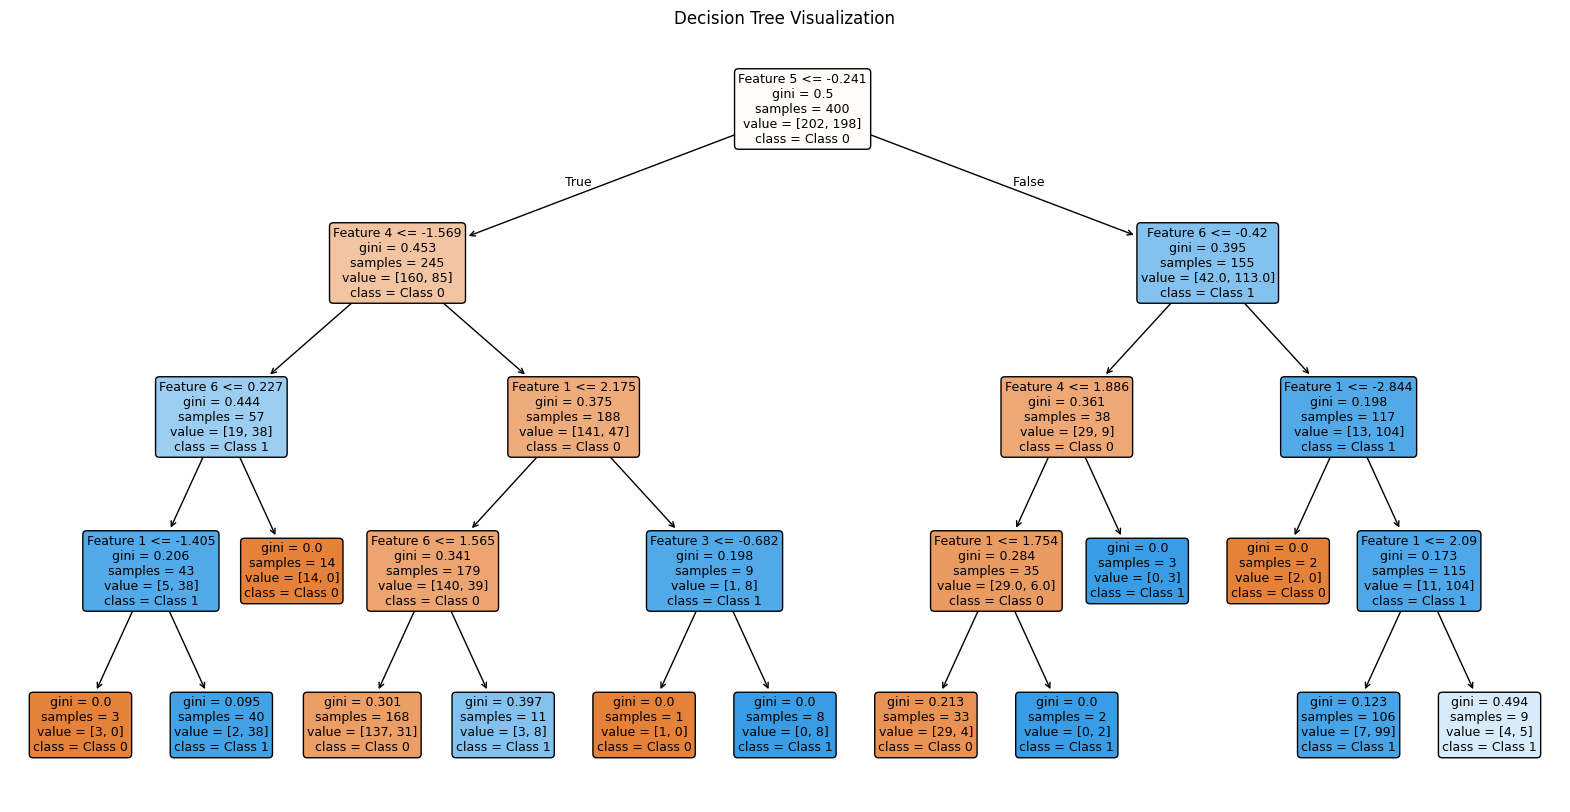



GINI vs ENTROPY
Gini Training Accuracy: 0.8725
Gini Validation Accuracy: 0.79

Entropy Training Accuracy: 0.86
Entropy Validation Accuracy: 0.81


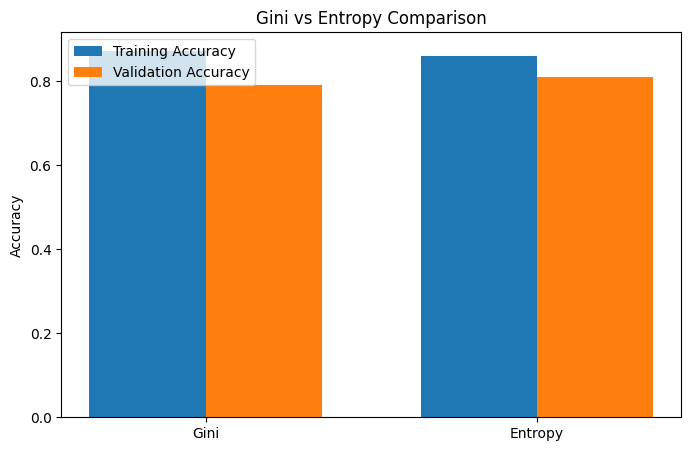



CCP PRUNING PATH
Number of CCP alpha values: 12

CCP Alpha values:
[0.         0.00444444 0.00593934 0.00728139 0.00803865 0.00948496
 0.01259302 0.01520607 0.01929159 0.039604   0.06097689 0.06930221]


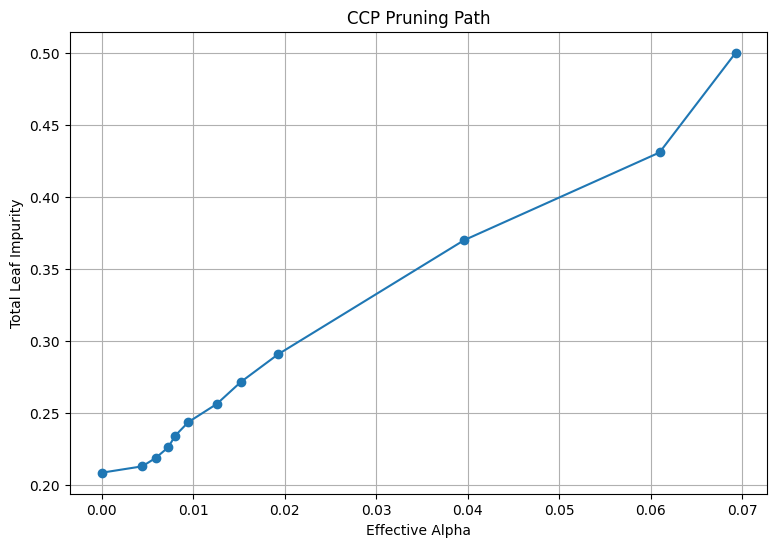

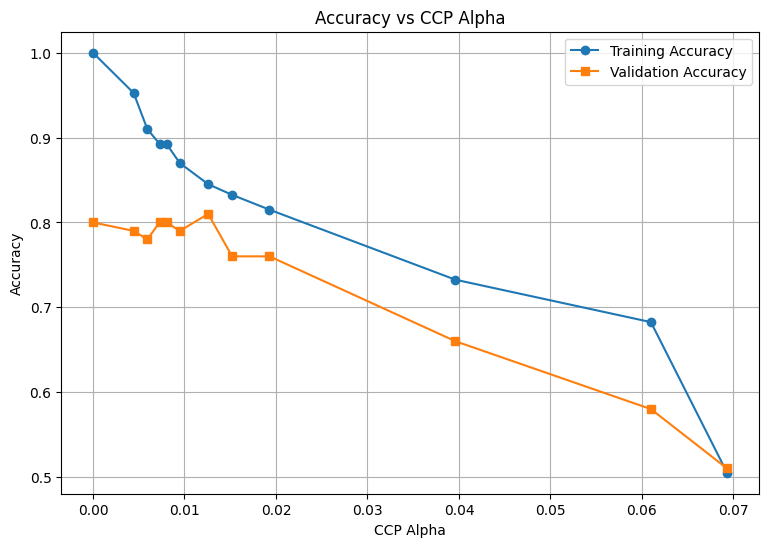



DECISION TREE DEPTH SWEEP
 depth  train_acc  val_acc  n_leaves
     1     0.6825     0.58         2
     2     0.7800     0.72         4
     3     0.8450     0.76         8
     4     0.8725     0.79        13
     5     0.8950     0.78        19
     6     0.9200     0.81        27
     7     0.9400     0.82        34
     8     0.9550     0.81        41
     9     0.9600     0.79        43
    10     0.9675     0.79        46
    11     0.9800     0.80        49
    12     0.9900     0.80        52
    13     0.9950     0.79        53
    14     1.0000     0.80        55
    15     1.0000     0.80        55


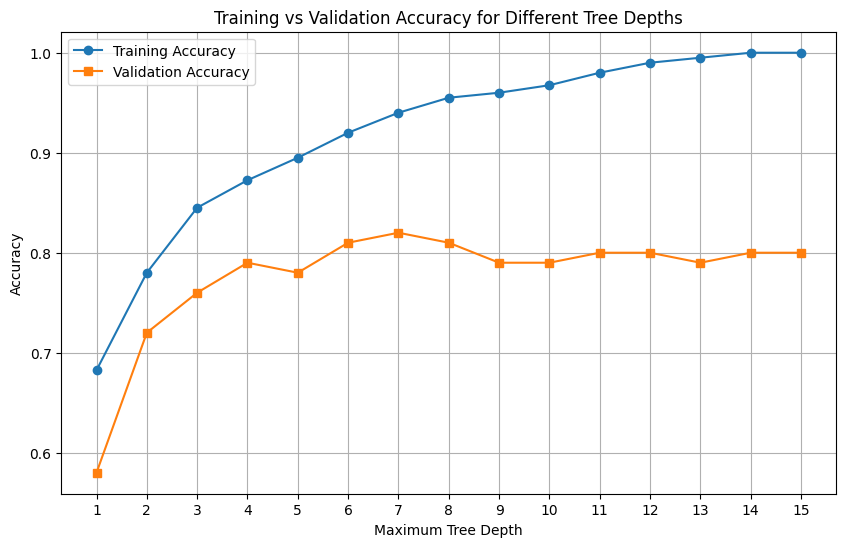

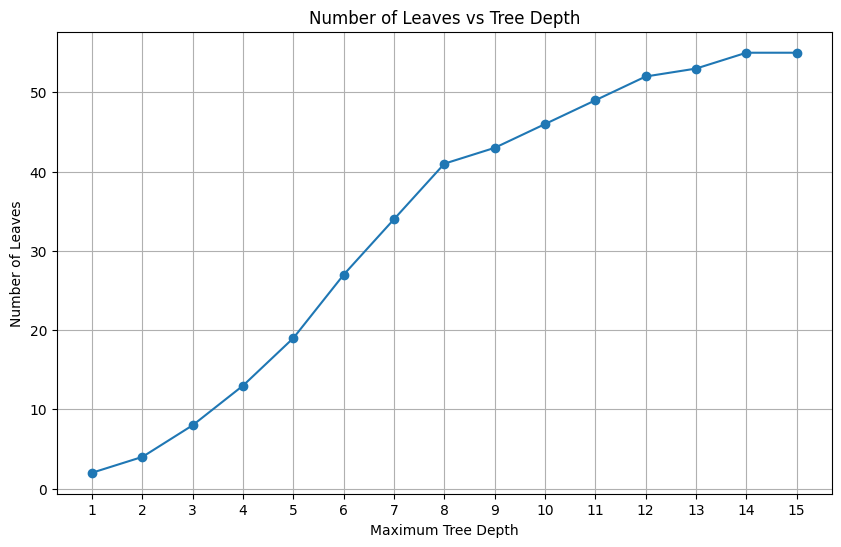



BEST DECISION TREE RESULT
Best Depth: 7
Training Accuracy: 0.94
Validation Accuracy: 0.82
Number of Leaves: 34

Best Row:
 depth  train_acc  val_acc  n_leaves
   7.0       0.94     0.82      34.0


FINAL DATAFRAME


,depth,train_acc,val_acc,n_leaves
0,1,0.6825,0.58,2
1,2,0.7800,0.72,4
2,3,0.8450,0.76,8
3,4,0.8725,0.79,13
4,5,0.8950,0.78,19
5,6,0.9200,0.81,27
6,7,0.9400,0.82,34
7,8,0.9550,0.81,41
8,9,0.9600,0.79,43
9,10,0.9675,0.79,46



Results saved as decision_tree_depth_results.csv


In [ ]:
# 1. IMPORT LIBRARIES
# ------------------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.tree import (
    DecisionTreeClassifier,
    plot_tree
)
from sklearn.metrics import (
    accuracy_score,
    classification_report
)


# ------------------------------------------------------------
# 2. CREATE DATASET
# ------------------------------------------------------------

X, y = make_classification(
    n_samples=500,
    n_features=6,
    n_informative=4,
    n_redundant=0,
    n_classes=2,
    random_state=42
)

print("Dataset created successfully")
print("X shape:", X.shape)
print("y shape:", y.shape)


# ------------------------------------------------------------
# 3. TRAIN-VALIDATION SPLIT
# ------------------------------------------------------------

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", X_train.shape[0])
print("Validation samples:", X_val.shape[0])


# ============================================================
# QUESTION 1
# BASIC DECISION TREE
# ============================================================

dt = DecisionTreeClassifier(
    criterion='gini',
    random_state=42,
    max_depth=4
)

dt.fit(
    X_train,
    y_train
)

train_pred = dt.predict(X_train)
val_pred = dt.predict(X_val)

print("\n")
print("=" * 60)
print("BASIC DECISION TREE")
print("=" * 60)

print(
    "Training Accuracy:",
    accuracy_score(y_train, train_pred)
)

print(
    "Validation Accuracy:",
    accuracy_score(y_val, val_pred)
)

print("\nClassification Report:")
print(
    classification_report(
        y_val,
        val_pred
    )
)


# ============================================================
# QUESTION 2
# PLOT TREE VISUALISATION
# ============================================================

plt.figure(figsize=(20, 10))

plot_tree(
    dt,
    filled=True,
    feature_names=[
        'Feature 1',
        'Feature 2',
        'Feature 3',
        'Feature 4',
        'Feature 5',
        'Feature 6'
    ],
    class_names=[
        'Class 0',
        'Class 1'
    ],
    rounded=True
)

plt.title(
    'Decision Tree Visualization'
)

plt.show()


# ============================================================
# QUESTION 3
# GINI vs ENTROPY COMPARISON
# ============================================================

# -----------------------------
# GINI MODEL
# -----------------------------

gini_model = DecisionTreeClassifier(
    criterion='gini',
    random_state=42,
    max_depth=4
)

gini_model.fit(
    X_train,
    y_train
)

gini_train_pred = gini_model.predict(
    X_train
)

gini_val_pred = gini_model.predict(
    X_val
)

gini_train_acc = accuracy_score(
    y_train,
    gini_train_pred
)

gini_val_acc = accuracy_score(
    y_val,
    gini_val_pred
)


# -----------------------------
# ENTROPY MODEL
# -----------------------------

entropy_model = DecisionTreeClassifier(
    criterion='entropy',
    random_state=42,
    max_depth=4
)

entropy_model.fit(
    X_train,
    y_train
)

entropy_train_pred = entropy_model.predict(
    X_train
)

entropy_val_pred = entropy_model.predict(
    X_val
)

entropy_train_acc = accuracy_score(
    y_train,
    entropy_train_pred
)

entropy_val_acc = accuracy_score(
    y_val,
    entropy_val_pred
)


# -----------------------------
# PRINT COMPARISON
# -----------------------------

print("\n")
print("=" * 60)
print("GINI vs ENTROPY")
print("=" * 60)

print(
    "Gini Training Accuracy:",
    gini_train_acc
)

print(
    "Gini Validation Accuracy:",
    gini_val_acc
)

print()

print(
    "Entropy Training Accuracy:",
    entropy_train_acc
)

print(
    "Entropy Validation Accuracy:",
    entropy_val_acc
)


# -----------------------------
# BAR CHART
# -----------------------------

criteria = [
    'Gini',
    'Entropy'
]

train_accuracy = [
    gini_train_acc,
    entropy_train_acc
]

validation_accuracy = [
    gini_val_acc,
    entropy_val_acc
]

x = np.arange(len(criteria))
width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(
    x - width/2,
    train_accuracy,
    width,
    label='Training Accuracy'
)

plt.bar(
    x + width/2,
    validation_accuracy,
    width,
    label='Validation Accuracy'
)

plt.xticks(
    x,
    criteria
)

plt.ylabel('Accuracy')

plt.title(
    'Gini vs Entropy Comparison'
)

plt.legend()

plt.show()


# ============================================================
# QUESTION 4
# CCP PRUNING PATH
# ============================================================

# Get pruning path

path = gini_model.cost_complexity_pruning_path(
    X_train,
    y_train
)

ccp_alphas = path.ccp_alphas
impurities = path.impurities

print("\n")
print("=" * 60)
print("CCP PRUNING PATH")
print("=" * 60)

print("Number of CCP alpha values:", len(ccp_alphas))

print("\nCCP Alpha values:")
print(ccp_alphas)


# -----------------------------
# PLOT CCP PRUNING PATH
# -----------------------------

plt.figure(figsize=(9, 6))

plt.plot(
    ccp_alphas,
    impurities,
    marker='o'
)

plt.xlabel(
    'Effective Alpha'
)

plt.ylabel(
    'Total Leaf Impurity'
)

plt.title(
    'CCP Pruning Path'
)

plt.grid(True)

plt.show()


# ============================================================
# QUESTION 5
# TEST DIFFERENT CCP ALPHA VALUES
# ============================================================

pruned_trees = []

for alpha in ccp_alphas:

    model = DecisionTreeClassifier(
        criterion='gini',
        random_state=42,
        ccp_alpha=alpha
    )

    model.fit(
        X_train,
        y_train
    )

    pruned_trees.append(model)


# Calculate accuracies

train_scores = [
    accuracy_score(
        y_train,
        model.predict(X_train)
    )
    for model in pruned_trees
]

val_scores = [
    accuracy_score(
        y_val,
        model.predict(X_val)
    )
    for model in pruned_trees
]


# -----------------------------
# PLOT PRUNING PERFORMANCE
# -----------------------------

plt.figure(figsize=(9, 6))

plt.plot(
    ccp_alphas,
    train_scores,
    marker='o',
    label='Training Accuracy'
)

plt.plot(
    ccp_alphas,
    val_scores,
    marker='s',
    label='Validation Accuracy'
)

plt.xlabel(
    'CCP Alpha'
)

plt.ylabel(
    'Accuracy'
)

plt.title(
    'Accuracy vs CCP Alpha'
)

plt.legend()

plt.grid(True)

plt.show()


# ============================================================
# QUESTION 6
# dt_report() FUNCTION
# ============================================================

def dt_report(
    X_train,
    y_train,
    X_val,
    y_val
):

    results = []

    # Sweep max_depth from 1 to 15
    for depth in range(1, 16):

        model = DecisionTreeClassifier(
            criterion='gini',
            max_depth=depth,
            random_state=42
        )

        model.fit(
            X_train,
            y_train
        )

        # Predictions
        train_pred = model.predict(
            X_train
        )

        val_pred = model.predict(
            X_val
        )

        # Accuracy
        train_acc = accuracy_score(
            y_train,
            train_pred
        )

        val_acc = accuracy_score(
            y_val,
            val_pred
        )

        # Number of leaves
        n_leaves = model.get_n_leaves()

        # Store result
        results.append([
            depth,
            train_acc,
            val_acc,
            n_leaves
        ])


    # Create DataFrame
    results_df = pd.DataFrame(
        results,
        columns=[
            'depth',
            'train_acc',
            'val_acc',
            'n_leaves'
        ]
    )

    return results_df


# ============================================================
# QUESTION 7
# CALL dt_report()
# ============================================================

results = dt_report(
    X_train,
    y_train,
    X_val,
    y_val
)


# ============================================================
# DISPLAY DEPTH RESULTS
# ============================================================

print("\n")
print("=" * 60)
print("DECISION TREE DEPTH SWEEP")
print("=" * 60)

print(
    results.to_string(index=False)
)


# ============================================================
# QUESTION 8
# PLOT TRAINING AND VALIDATION ACCURACY
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    results['depth'],
    results['train_acc'],
    marker='o',
    label='Training Accuracy'
)

plt.plot(
    results['depth'],
    results['val_acc'],
    marker='s',
    label='Validation Accuracy'
)

plt.xlabel(
    'Maximum Tree Depth'
)

plt.ylabel(
    'Accuracy'
)

plt.title(
    'Training vs Validation Accuracy for Different Tree Depths'
)

plt.xticks(
    range(1, 16)
)

plt.legend()

plt.grid(True)

plt.show()


# ============================================================
# QUESTION 9
# PLOT NUMBER OF LEAVES
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    results['depth'],
    results['n_leaves'],
    marker='o'
)

plt.xlabel(
    'Maximum Tree Depth'
)

plt.ylabel(
    'Number of Leaves'
)

plt.title(
    'Number of Leaves vs Tree Depth'
)

plt.xticks(
    range(1, 16)
)

plt.grid(True)

plt.show()


# ============================================================
# QUESTION 10
# FIND BEST VALIDATION ACCURACY
# ============================================================

best_row = results.loc[
    results['val_acc'].idxmax()
]


print("\n")
print("=" * 60)
print("BEST DECISION TREE RESULT")
print("=" * 60)

print(
    "Best Depth:",
    int(best_row['depth'])
)

print(
    "Training Accuracy:",
    best_row['train_acc']
)

print(
    "Validation Accuracy:",
    best_row['val_acc']
)

print(
    "Number of Leaves:",
    int(best_row['n_leaves'])
)


# ============================================================
# QUESTION 11
# PRINT BEST ROW
# ============================================================

print("\nBest Row:")

print(
    best_row.to_frame().T.to_string(
        index=False
    )
)


# ============================================================
# QUESTION 12
# FINAL DATAFRAME
# ============================================================

print("\n")
print("=" * 60)
print("FINAL DATAFRAME")
print("=" * 60)

display(results)


# ============================================================
# QUESTION 13
# SAVE RESULTS
# ============================================================

results.to_csv(
    'decision_tree_depth_results.csv',
    index=False
)

print(
    "\nResults saved as decision_tree_depth_results.csv"
)
